# Short-wave infrared (version 1.1)

Version 1.1 of the look-up tables adds the wavelengths 1600, 2200 and 2500 nm to the 350-1000 nm of
version 1.0 (Harmel, 2023). They come from the same OSOAA computations and the same recipe: the
values of 350-1000 nm are those of version 1.0, unchanged.

In the short-wave infrared (SWIR), the water body is practically black, so that the radiance above
the surface is the surface-reflected light only: SWIR bands are used to check or correct the
sky glint and sunglint residuals of the visible bands.

```{warning}
The radiative transfer computations do not include the gaseous absorption. Use the SWIR values in
the atmospheric windows only (about 1040-1070, 1240, 1550-1700 and 2100-2250 nm), away from the water
vapour bands (940, 1140, 1380, 1880 nm) and the CO2 / CH4 bands (2000-2060, > 2300 nm). The 2500 nm
node is at the edge of strong absorption bands. Do not interpolate between 1000 and 1600 nm across
the 1380 nm band.
```

In [1]:
import matplotlib.pyplot as plt

from surface_sky_radiance_ratio import lut

rss = lut()
ds = rss.load()
ds.wl.values

array([ 350.,  400.,  500.,  600.,  700.,  800., 1000., 1600., 2200.,
       2500.], dtype=float32)

## Spectra from 350 to 2500 nm

The main absorption bands of the atmosphere are shaded. $R_{ss}$ decreases in the SWIR, partly because
the refractive index of water decreases (about 1.33 at 500 nm, 1.27 at 2500 nm), which lowers the Fresnel
reflectance.

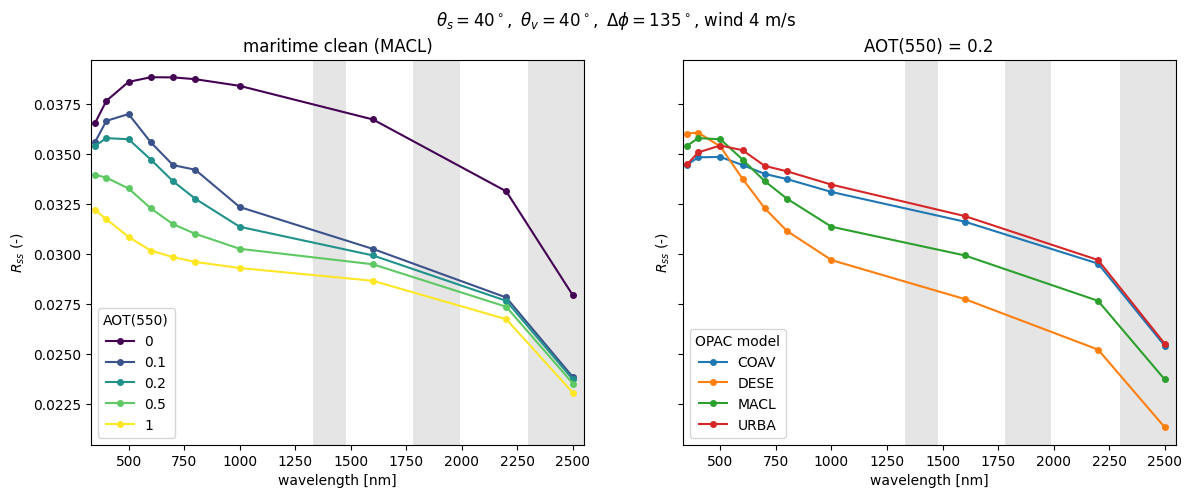

In [2]:
BANDS = [(1330, 1480), (1780, 1990), (2300, 2600)]   # strong H2O / CO2 / CH4 absorption


def shade(ax):
    for lo, hi in BANDS:
        ax.axvspan(lo, hi, color='grey', alpha=0.2, lw=0)


geom = dict(sza=40, vza=40, azi=135, wind=4)
fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
cmap = plt.cm.viridis
aots = [0, 0.1, 0.2, 0.5, 1.0]
for i, aot in enumerate(aots):
    ds.Rss.sel(model='MACL_rh70').interp(**geom, aot_ref=aot).plot(
        ax=axs[0], color=cmap(i / (len(aots) - 1)), marker='o', ms=4, label=f'{aot:g}')
axs[0].legend(title='AOT(550)')
axs[0].set_title('maritime clean (MACL)')
for model in ds.model.values:
    ds.Rss.sel(model=model).interp(**geom, aot_ref=0.2).plot(
        ax=axs[1], marker='o', ms=4, label=model.split('_')[0])
axs[1].legend(title='OPAC model')
axs[1].set_title('AOT(550) = 0.2')
for ax in axs:
    shade(ax)
    ax.set_xlim(330, 2550)
    ax.set_ylabel(r'$R_{ss}$ (-)')
fig.suptitle(r'$\theta_s=40^\circ,\ \theta_v=40^\circ,\ \Delta\phi=135^\circ$, wind 4 m/s');

## Sun zenith angle dependence in the SWIR

In the SWIR the molecular scattering is negligible: the sky radiance comes from the aerosols and is
very low for a clear atmosphere. $R_{ss}$ stays well defined in the simulations, but a measured
$L_{sky}$ close to the noise level of the radiometer makes the correction term $R_{ss} L_{sky}$
poorly constrained.

For the usual geometries (viewing zenith 25-55°, relative azimuth 45-160°, Sun zenith up to 80°), the
SWIR values span the same range as at 1000 nm (about 0.003-0.2). Much larger values (up to 1.7 at
2500 nm) only occur for the Sun at the horizon ($\theta_s > 80^\circ$) with a very clear atmosphere,
where the sky radiance of the specular direction is almost nil: avoid these conditions in the SWIR.

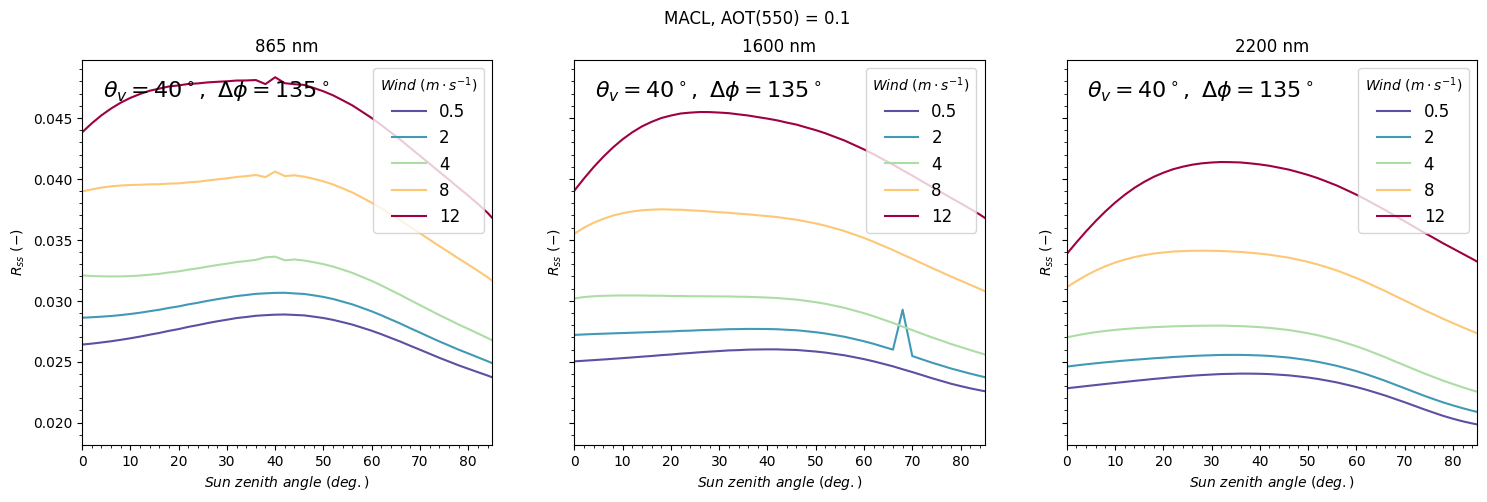

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, wl in zip(axs, [865, 1600, 2200]):
    rss.plot_vs_sza(ax=ax, vza=40, azi=135, wl=wl, model='MACL_rh70', aot_ref=0.1)
    ax.set_title(f'{wl} nm')
fig.suptitle('MACL, AOT(550) = 0.1');

## Use on SWIR bands

As for the visible bands, interpolate the table on the band centres, keeping to the tabulated SWIR nodes
or their close vicinity, e.g. for Sentinel-2-like bands at 1610 and 2190 nm:

In [4]:
ds.Rss.sel(model='MACL_rh70').interp(sza=40, vza=40, azi=135, wind=4, aot_ref=0.1, wl=[1610, 2190])

<xarray.DataArray 'Rss' (wl: 2)> Size: 16B
array([0.03022515, 0.02787751])
Coordinates:
  * wl              (wl) int64 16B 1610 2190
    model           <U9 36B 'MACL_rh70'
    slope_variance  float64 8B 0.02348
    sza             int64 8B 40
    vza             int64 8B 40
    azi             int64 8B 135
    wind            int64 8B 4
    aot_ref         float64 8B 0.1
Attributes:
    long_name:    surface-to-sky radiance ratio
    description:  tabulated values of Rss for correction of surface radiance ...
    units:        -
    author:       Tristan Harmel
    reference:    Harmel, T. (2023). Apparent surface-to-sky radiance ratio o...
    version:      1.1